## STEP 0: Generation of Matrix

In [18]:
import numpy as np

# Visualization setings
np.set_printoptions(precision=6, suppress=True)

def gerar_matrizes(matricula) :
    """
    Gera as matrizes dos Problemas 1 e 2 a partir de uma matrícula com 6 digitos .
    """
    digitos = [int(d) for d in str(matricula)]

    if len(digitos) != 6:
        raise ValueError("A matrícula deve possuir exatamente 6 digitos.")

    d1, d2, d3, d4, d5, d6 = digitos

    # Problema 1
    A1 = np.array([
    [17 + d1, d2, 34 + d3, 24 + d4],
    [7 + d5, 15 + d6, 3 + d1, 9 + d2],
    [2, 0, d3, 31],
    [0, 0, 0, 31 + d4]
    ], dtype=float)

    # Problema 2
    A2 = np . array ([
    [-5 - d1, -1, 0, 2, 1],
    [-7, -1 - d2, 9, 7, 2],
    [4, 3, 8 + d3, -2, -2],
    [-7, 3, 4, -6 - d4, -2],
    [0, -2, -7, -7, -9 - d5]
    ], dtype=float)

    return A1, A2

matricula = 318375
A1, A2 = gerar_matrizes(matricula)

print("\nMatriz do Problema 1: ")
print(A1)
print("\nMatriz do Problema 2: ")
print(A2)


Matriz do Problema 1: 
[[20.  1. 42. 27.]
 [14. 20.  6. 10.]
 [ 2.  0.  8. 31.]
 [ 0.  0.  0. 34.]]

Matriz do Problema 2: 
[[ -8.  -1.   0.   2.   1.]
 [ -7.  -2.   9.   7.   2.]
 [  4.   3.  16.  -2.  -2.]
 [ -7.   3.   4.  -9.  -2.]
 [  0.  -2.  -7.  -7. -16.]]


Na matriz $A_1$, o elemento $a_{31} = 2 \neq 0$, assim a matriz não está na forma de Hessenberg superior (elementos abaixo da subdiagonal iguais a zero), com isso, temos um impedimento de uso direto do algoritmo QR sobre esta matriz porque:

1. A fatoração QR via Householder ou Gram-Schmidt modificado custa $O(n^3)$ operações de ponto flutuante. Como a convergência global para a matriz de Schur exige $O(n)$ iterações, o esforço computacional total escalaria para $O(n^4)$.
    
    1.1 Se $A$ for previamente reduzida a uma matriz de Hessenberg superior $H$, a estrutura esparsa abaixo da subdiagonal permite que a fatoração $H=QR$ aniquile apenas um único elemento por coluna, substituindo o uso pesado de Householder por uma sequência de $n - 1$ rotações de Givens planas, levando o custo computacional de $O(n^3)$ para $O(n^2)$. Assim, o custo global de convergência cai para $O(n^3)$.

2. A matriz de Hessenberg é invariante sob a iteração QR: se $H_{k} = Q_{k}R_{k}$ é a fatoração de uma matriz de Hessenberg superior, a próxima matriz na sequência de similaridade, $H_{k+1} = Q_{k+1}R_{k+1}$, também é garantidamente de Hesseberg superior. O algoritmo QR revela os autovalores conduzindo os elementos subdiagonais a zero. Quando um elemento subdiagonal atinge uma magnitude tolerável próxima ao épsilon da aritmética de máquina,  $\epsilon_{mach}$, a matriz experimenta o fenômeno de "deflação" ou "desacoplamento espectral", particionando-se em blocos: $H = \begin{bmatrix} H_{11} & H_{12} \\ 0 & H_{22} \end{bmatrix}$. Isso quebra o problema original de dimensão $n$ em subproblemas independentes e menores, permitindo que as iterações subsequentes foquem apenas no bloco ativo.

Além disso, na linha 4 de $A_1$ o elemento $a_{43} = 0$ já está desacoplado, o que implica que $\lambda = 34$ já é um autovalor visível por inspeção, e o algoritmo de Hessenberg + QR preservará essa estrutura.

## STEP 1: The Hessenberg Reduction

No problema 1a nosso objetivo é obter a Decomposição Real de Schur: $A = QTQ^T \iff Q^TAQ = T$, onde $Q \in \mathbb{R}^{n \times n}$ é ortogonal ($Q^TQ = I$) e $T \in \mathbb{R}^{n \times n}$ é quase triangular superior (triangular superior em blocos $1 \times 1$ para autovalores reais e blocos $2 \times 2$ para pares de autovalores complexos conjugados).
Assim, precisamos primeiramente contruir uma matriz ortogonal $U = P_1P_2 \dots P_{n-2}$ (produto de reflexões de Householder), tal que:

$$H = U^TAU$$

seja Hessenberg superior. Com isso, aplicando as rotações de Givens sobre $H$ e acumulando-as na própria matriz ortogonal, obteremos a matriz $Q$ final da decomposição de Schur.

### 1.1. Reflexão de Householder

Dado um vetor coluna $x \in \mathbb{R}^m$, queremos encontrar um vetor $v \in \mathbb{R}^m$ e uma constante $c = \frac{2}{v^Tv}$ tais que a matriz de reflexão de Householder:

$$P = I - cvv^T$$

reflita $x$ sobre o primeiro eixo canônico $e_1 = [1, 0, \dots, 0]^T$, zerando todas as componentes de $x$ abaixo da primeira:

$$Px = (I - cvv^T)x = \alpha e_1, \text{onde } \alpha = \pm \|x\|_2$$

Para construir $v$ de forma numericamente estável, evitando cancelamento catastrófico na subtração de números de mesmo sinal:

1. Calculamos a norma euclidiana $\|x\|_2 = \sqrt{\sum_{i=1}^m x_i^2}$ com a função `calc_norm_2()`:

In [19]:
# Calculation of norm-2
def calc_norm_2(x: np.ndarray) -> float:
    """Calculates the euclidian norm-2 of a vector: sqrt(x^T x)."""
    return float(np.sqrt(np.sum(x ** 2)))

2. Escolhemos o sinal de $\alpha$ oposto ao sinal da primeira componente $x_1$:
$$\alpha = -\operatorname{sign}(x_1)\|x\|_2 \quad (\text{usando }\operatorname{sign}(x_1) = 1 \text{ se } x_1 \ge 0 \text{ e } -1 \text{ se } x_1 < 0)$$

3. Definimos o vetor de Householder:
$$v = x - \alpha e_1 \implies \begin{cases} v_1 = x_1 - \alpha = x_1 + \operatorname{sign}(x_1)\|x\|_2 \\ v_i = x_i, \quad \text{para } i = 2, \dots, m \end{cases}$$

4. Calculamos $c = \frac{2}{v^Tv}$ (com a proteção de que, se $vTv = 0$, então $c = 0$).

A função `house()` implementa os passos 2, 3 e 4 descritos anteriormente:

In [20]:
# Calculation of Householder Reflexition
def house(x: np.ndarray):
    """
    Calculates the vextor v of Householder and the scalar c = 2 / (v^T v)
    such that P*x = (I - c * v * v^T)*x = alpha * e_1
    """
    # Ensuring that x is treated as a 1D vector to facilitate manipulation
    x_vec = x.flatten().astype(float).copy()
    x_norm = calc_norm_2(x_vec)

    # If all the entries below x[0] are already zero, we don't need to reflect.
    if calc_norm_2(x_vec[1:]) == 0:
        v = np.zeros_like(x_vec).reshape(-1, 1)     # Copy vector x with entries equal to 0, and transform v into a column vector (m x 1)
        c = 0.0
        return v, c
    
    # Item 2: Choose the opposite alpha sign to x[0] to avoid catastrophic cancellation.
    sign = 1.0 if x_vec[0] >= 0.0 else -1.0
    alpha = -sign * x_norm

    # Item 3: v = x - alpha * e_1
    v = x_vec.copy()
    v[0] = v[0] - alpha
    v = v.reshape(-1, 1)        # Transform v into a column vector (m x 1)

    # Item 4: c = 2 / (v^T v)
    vTv = float((v.T @ v)[0, 0])        # [0, 0] extracts the pure scalar
    c = 2.0 / vTv if vTv > 0.0 else 0.0

    return v, c

### 1.2 Hessenberg Reduction
A função `hessenberg_reduction()` implementa o algoritmo de redução de Hessenberg, recebendo uma matriz $A \in \mathbb{R}^{n \times n}$ e tendo como saída a matriz ortogonal $U$ e a matriz de Hessinberg superior $H$, tais que $H = U^TAU$. Nesta função, no passo $j$ começamos na linha $j + 1$ into até $n$: $x = H(j + 1:n, j)$. Assim:

* Multiplicar à esquerda por $P_j^T$ combina apenas as linhas $j + 1$ até $n$, zerando as entradas $j + 2$ até $n$ da coluna $j$ abaixo da subdiagonal.
* Multiplicar à direita por $P_j$ combina apenas as colunas $j + 1$ até $n$, não alterando a coluna $j$ e preservando os zeros recém-criados.

Se usássemos uma reflexão $P_1$ para zerar as entradas 2 até $n$ da primeira coluna, como fazemos na fatoração QR tradicional, ao multiplicarmos à direita na transformação de similaridade $P_1^TAP_1$, a multiplicação por $P_1$ combinaria a primeira coluna com as demais e destruiria todos os zeros já criados.

In [21]:
def hessenberg_reduction(A: np.ndarray):
    """Hessenberg Reduction algorithm."""
    n = A.shape[0]
    U = np.eye(n, dtype=float)
    H = A.astype(float).copy()

    for j in range(n - 2):
        # v = house(H(j+1:n, j)), c = 2 / (v^T v)
        x_sub = H[j + 1 : n, j]
        v, c = house(x_sub)

        if c != 0.0:
            # H(j+1:n, j:n) = H(j+1:n, j:n) - c * v * (v^T * H(j+1:n, j:n))
            H[j + 1 : n, j:n] = H[j + 1 : n, j:n] - c * (
                v @ (v.T @ H[j + 1 : n, j:n])
            )

            # H(1:n, j+1:n) = H(1:n, j+1:n) - c * (H(1:n, j+1:n) * v) * v^T
            H[:, j + 1 : n] = H[:, j + 1 : n] - c * ((H[:, j + 1 : n] @ v) @ v.T)

            # U(1:n, j+1:n) = U(1:n, j+1:n) - c * (U(1:n, j+1:n) * v) * v^T
            U[:, j + 1 : n] = U[:, j + 1 : n] - c * ((U[:, j + 1 : n] @ v) @ v.T)

    return U, H

In [26]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

# ==============================================================================
# DEFINIÇÃO DA PALETA FÍSICA DE ENERGIA
# -infinito -> Preto / Vermelho escuro (mínimo de energia)
# 0.00      -> Branco puro (estado neutro / zero de energia)
# +infinito -> Violeta profundo (máximo de energia)
# ==============================================================================
nos_cores = [
    (0.00, "#1a0002"),  # Preto / Vermelho profundíssimo (-infinito)
    (0.12, "#800000"),  # Vermelho escuro (-15.00)
    (0.30, "#d32f2f"),  # Vermelho vivo
    (0.44, "#ef9a9a"),  # Rosa salmão claro visível
    (0.50, "#ffffff"),  # BRANCO PURO EXCLUSIVO PARA O ZERO (0.00)
    (0.53, "#64b5f6"),  # Azul celeste nítido (+1.0 a +2.0)
    (0.70, "#1976d2"),  # Azul clássico
    (0.88, "#4a148c"),  # Violeta (+42.00)
    (1.00, "#1a0033"),  # Violeta escuro (+infinito)
]
cmap_fisica = LinearSegmentedColormap.from_list(
    "escala_fisica", nos_cores, N=513
)


def renderizar_matriz(
    ax, matriz, titulo, vmin=None, vmax=None, threshold_zero=1e-10
):
  """Renderiza uma matriz como mapa de calor com escala física de energia."""
  matriz_plot = matriz.copy()
  matriz_plot[np.abs(matriz_plot) < threshold_zero] = 0.0

  if vmin is None or vmax is None:
    max_val = np.max(np.abs(matriz))
    norm = TwoSlopeNorm(
        vmin=-max_val if max_val > 0 else -1.0,
        vcenter=0.0,
        vmax=max_val if max_val > 0 else 1.0,
    )
  else:
    norm = TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax)

  cax = ax.matshow(matriz_plot, cmap=cmap_fisica, norm=norm)

  for i in range(matriz.shape[0]):
    for j in range(matriz.shape[1]):
      valor = matriz[i, j]

      if abs(valor) < threshold_zero:
        texto = "0"
        cor_texto = "black"
        peso = "bold"
      else:
        texto = f"{valor:.2f}"
        val_norm = norm(valor)
        cor_texto = "white" if (val_norm < 0.22 or val_norm > 0.78) else "black"
        peso = "normal"

      ax.text(
          j,
          i,
          texto,
          va="center",
          ha="center",
          color=cor_texto,
          weight=peso,
          fontsize=11,
      )

  ax.set_title(titulo, pad=15, fontsize=12, fontweight="bold")
  ax.set_xticks(range(matriz.shape[1]))
  ax.set_yticks(range(matriz.shape[0]))
  return cax


def visualizar_reducao(A, H, U):
  fig, axes = plt.subplots(1, 3, figsize=(18, 7.5))
  fig.patch.set_facecolor("#f8f9fa")

  # 1. Matriz Original ($A_1$)
  renderizar_matriz(
      axes[0], A, "Matriz Original ($A_1$)", vmin=-15.0, vmax=42.0
  )

  # 2. Matriz de Hessenberg ($H$)
  cax_H = renderizar_matriz(
      axes[1],
      H,
      "Matriz de Hessenberg ($H = U^T A_1 U$)",
      vmin=-15.0,
      vmax=42.0,
  )

  # 3. Matriz Ortogonal ($U$)
  renderizar_matriz(
      axes[2],
      U,
      "Matriz Ortogonal de Transformação ($U = U^T$)",
      vmin=-1.0,
      vmax=1.0,
  )

  # Barra de cores horizontal como legenda
  cbar_ax = fig.add_axes([0.28, 0.12, 0.44, 0.035])
  cbar = fig.colorbar(cax_H, cax=cbar_ax, orientation="horizontal")
  cbar.set_ticks([-15, 0, 42])
  cbar.set_ticklabels([
      r"$-\infty$",
      r"$0$",
      r"$+\infty$",
  ])
  cbar.ax.tick_params(labelsize=10.5)


  # Verificações de Sanidade (Norma do Supremo)
  erro_ortogonalidade = np.max(np.abs(U.T @ U - np.eye(A.shape[0])))
  erro_similaridade = np.max(np.abs(U @ H @ U.T - A))

  texto_metricas = (
      f"Erro de Ortogonalidade $||U^T U - I||_{{\\infty}}$ :"
      f" {erro_ortogonalidade:.2e}   |   Erro de Reconstrução $||U H U^T -"
      f" A_1||_{{\\infty}}$ : {erro_similaridade:.2e}"
  )

  plt.figtext(
      0.5,
      0.02,
      texto_metricas,
      ha="center",
      fontsize=11,
      bbox={
          "facecolor": "white",
          "alpha": 0.9,
          "pad": 8,
          "edgecolor": "#cccccc",
      },
  )

  plt.subplots_adjust(top=0.92, bottom=0.25, left=0.05, right=0.95, wspace=0.25)
  plt.show()


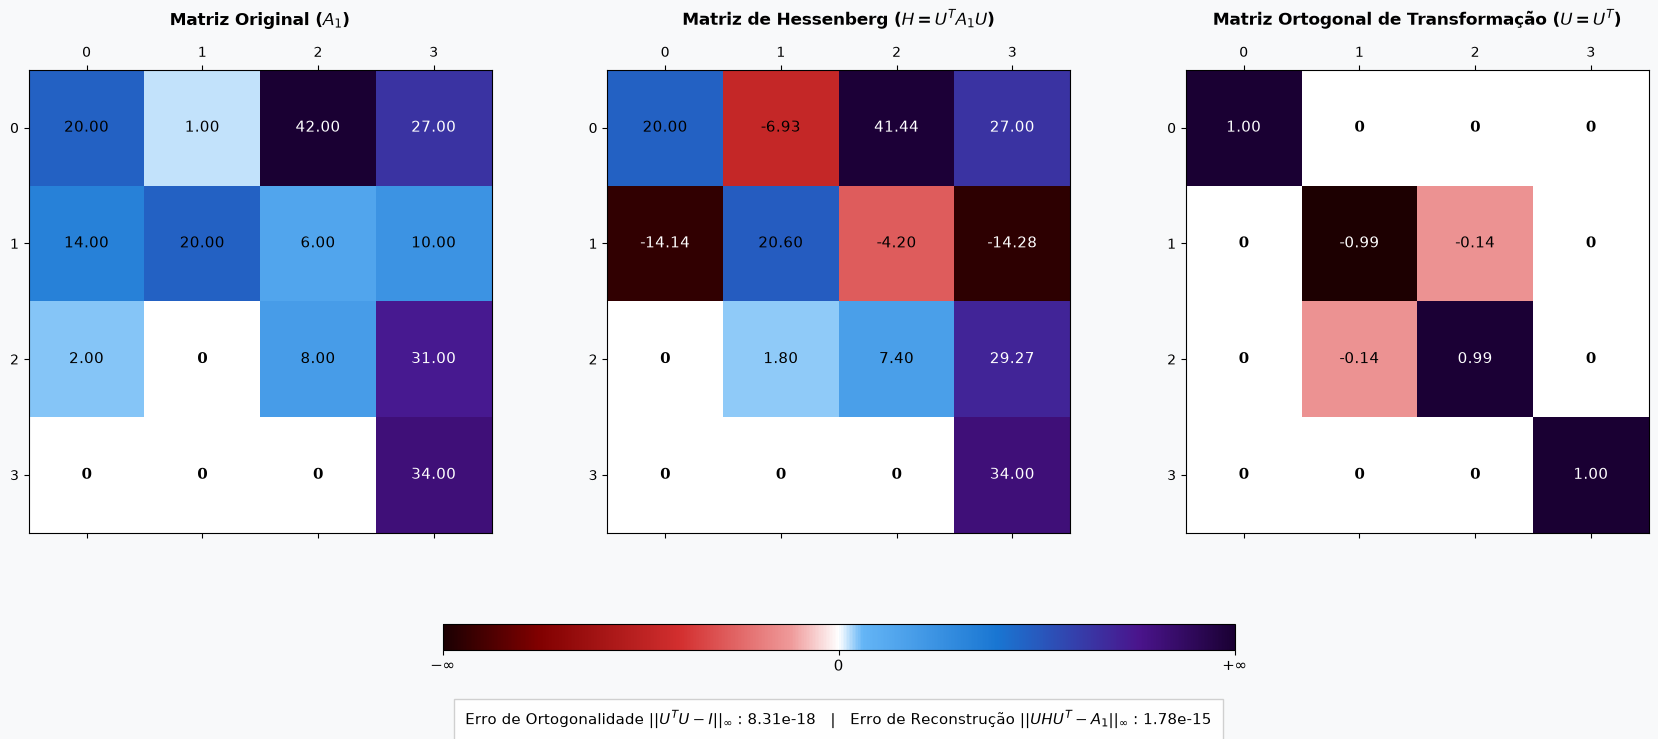

In [27]:
U, H = hessenberg_reduction(A1)
visualizar_reducao(A1, H, U)

Para zerar as entradas da primeira coluna de $A_1$ abaixo da primeira subdiagonal, aniquilando o $2.00$ na posição $a_{31}$ (posição $(2, 0)$ em Python) usando o $14.00$ na posição $a_{21}$ ($(1, 0)$ em Python) como pivô, o algoritmo extrai o subvetor ativo:

$$x = \begin{bmatrix} 14.00 \\ 2.00 \\ 0 \end{bmatrix}$$

A norma-2 deste vetor,

$$\|x\|_2 = \sqrt{14^2 + 2^2 + 0^2} = \sqrt{200} \approx 14.1421\dots$$

será concentrada na subdiagonal de $H$. Para evitar cancelamento catastrófico, o algoritmo projeta $x$ no vetor $-\|x\|_2e_1$, gerando o vetor de reflexão de Householder $v$:

$$v = x - (-\|x\|_2)e_1 = \begin{bmatrix} 14.00 \\ 2.00 \\ 0 \end{bmatrix} + \begin{bmatrix} 14.1421\dots \\ 0 \\ 0 \end{bmatrix} \approx \begin{bmatrix} 28.14 \\ 2.00 \\ 0 \end{bmatrix}$$

A matriz ortogonal local é construída via $P = I - cvv^T$, onde $c = \frac{2}{v^Tv}$. Analisando os elementos da matriz $U$, por exemplo $u_{32} = u_{23} = -0.14$, este elemento é calculado pelo produto cruzado dos componentes de $v$:

$$u_{32} = u_{23} = 0 - c \cdot v_1 \cdot v_2$$

onde $v_1 \approx 28.142$ e $v_2 = 2$ e a multiplicação garantindo a existência de um valor não-nulo fora da diagonal. Ao realizarmos a aritmética completa com o escalar $c$:

$$u_{32} \approx - \left(\frac{2}{28.142^2 + 2^2}\right) \cdot (28.142) \cdot (2) \approx -0.14142...$$

Além disso, observando a submatriz central $2 \text{ x } 2$ de $U$:

$$\begin{bmatrix} -0.99 & -0.14 \\ -0.14 & 0.99 \end{bmatrix}$$

vemos uma matriz de reflexão no $\mathbb{R}^2$, que tem a forma

$$\begin{bmatrix} -\cos(2\theta) & -\sin(2\theta) \\ -\sin(2\theta) & \cos(2\theta) \end{bmatrix}$$

Diante do exposto, podemos afirmar que a entrada $a_{31} = 2.00$ foi zerada, $h_{31} = 0$, na matriz $H$.

## STEP 2: Hessenberg's QR Iterative Step with Givens Rotations

Com a matriz $A_1$ reduzida à forma de Hessenberg superior $H = U^TA_1U$, o objetivo agora é aplicar sucessivas transformações ortogonais de similaridade sobre $H$ até que ela convirja para a matriz quase triangular superior $T$ da Decomposição Real de Schur:

$$A_1 = QTQ^T$$

extraindo em seguida os autovalores de $A_1$.

### 2.1. Custo assintótico dos métodos

#### Rotações de Givens

Vale ressaltar que um dos objetivos, em outras palavras, é aniquilar as entradas da subdiagonal da matriz $H$, no caso $h_{21} = -14.14$ e $h_{32} = 1.80$. Uma matriz de rotação de Givens $G_j$ atua no plano bidimensional através da submatriz $2 \text{ x } 2$:

$$\begin{bmatrix} G_{jj} & G_{jj+1} \\ G_{j+1j} & G_{j+1j+1} \end{bmatrix} = \begin{bmatrix} -\cos & -\sin \\ -\sin & \cos \end{bmatrix}$$

Aplicando esta matriz $G_j$ sobre $H$ temos $4$ multiplicações e $2$ adições, logo, $6$ operações de ponto flutuante (flops) por coluna, indo de $j \to n$, então:

$$\sum_{j=1}^{n-1} 6(n-j) = 6 \sum_{k=1}^{n-1} k = 6 \left(\frac{n(n-1)}{2}\right) = 3n^2 - 3n$$

Assintoticamente, a fatoração $H = QR$ custa $\mathcal{O}(n^2)$.

O algoritmo QR exige que a matriz ortogonal seja aplicada à direita para completar a transformação de similaridade:

$$H_{\text{next}} = R Q = R (G_1^T G_2^T \dots G_{n-1}^T)$$

Somando ambas as etapas, a iteração QR completa usando Givens em uma matriz de Hessenberg exige $\approx 6n^2 = \mathbf{\mathcal{O}(n^2)}$ flops.

#### Reflexão de Householder

Se aplicarmos o algoritmo QR diretamente sobre uma matriz densa usando matrizes de reflexão de Householder $P_j = I - 2vv^T$ temos outro cenário. O vetor de reflexão $v$ tem dimensão $n-j+1$. A atualização da submatriz $(n-j+1) \times (n-j+1)$ à direita e abaixo do pivô exige calcular o produto exterior $v (v^T A)$, o que consome aproximadamente $4(n-j)^2$ flops. Integrando esse custo sobre todas as colunas obtemos $\frac{4}{3}n^3$, ou seja, o limite de $\mathbf{\mathcal{O}(n^3)}$ operações de ponto flutuante.

### 2.2. A função `givens(a, b)`